# Part I — Exploratory Analysis: Ford GoBike System Data

## Introduction

This notebook explores the **Ford GoBike System** trip data from February 2019, covering 183,412 bike-sharing trips in the San Francisco Bay Area.

### Research Questions

1. **What factors affect trip duration?** — How long do people ride, and what influences it?
2. **How do usage patterns differ between Subscribers and Customers?** — Do membership types show distinct riding behaviors?
3. **What are the temporal patterns of bike usage?** — When do people ride (hour, day of week)?

### Dataset Variables

| Variable | Description |
|----------|-------------|
| `duration_sec` | Trip length in seconds |
| `start_time` / `end_time` | Trip timestamps |
| `start_station_*` / `end_station_*` | Station names and coordinates |
| `user_type` | Subscriber (annual member) or Customer (casual) |
| `member_birth_year` | Rider's birth year |
| `member_gender` | Rider's gender |
| `bike_share_for_all_trip` | Discount program flag |


In [1]:
# Standard imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Notebook display settings
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

def format_plot(ax, title, xlabel, ylabel):
    """Apply consistent formatting to a matplotlib axes object."""
    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.tick_params(labelsize=10)
    return ax


## Preliminary Wrangling

In [2]:
# Load data using relative path
df = pd.read_csv('201902-fordgobike-tripdata.csv')
print(f"Shape: {df.shape}")
print(f"\nData types:\n{df.dtypes}")


Shape: (183412, 16)

Data types:
duration_sec                 int64
start_time                     str
end_time                       str
start_station_id           float64
start_station_name             str
start_station_latitude     float64
start_station_longitude    float64
end_station_id             float64
end_station_name               str
end_station_latitude       float64
end_station_longitude      float64
bike_id                      int64
user_type                      str
member_birth_year          float64
member_gender                  str
bike_share_for_all_trip        str
dtype: object


In [3]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nTotal rows with any missing: {df.isnull().any(axis=1).sum()}")


Missing values per column:
duration_sec                  0
start_time                    0
end_time                      0
start_station_id            197
start_station_name          197
start_station_latitude        0
start_station_longitude       0
end_station_id              197
end_station_name            197
end_station_latitude          0
end_station_longitude         0
bike_id                       0
user_type                     0
member_birth_year          8265
member_gender              8265
bike_share_for_all_trip       0
dtype: int64

Total rows with any missing: 8460


In [4]:
# Convert timestamps to datetime
df['start_time'] = pd.to_datetime(df['start_time'])
df['end_time'] = pd.to_datetime(df['end_time'])

# Create derived features
df['duration_min'] = df['duration_sec'] / 60                       # duration in minutes
df['hour'] = df['start_time'].dt.hour                               # hour of day (0-23)
df['day_of_week'] = df['start_time'].dt.day_name()                  # day name
df['age'] = 2019 - df['member_birth_year']                          # approximate age

# Ordered day-of-week for plotting
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['day_of_week'] = pd.Categorical(df['day_of_week'], categories=day_order, ordered=True)

print("Derived features created.")
print(f"Duration range: {df['duration_min'].min():.1f} – {df['duration_min'].max():.1f} min")
print(f"Age range (before cleaning): {df['age'].min():.0f} – {df['age'].max():.0f}")


Derived features created.
Duration range: 1.0 – 1424.1 min
Age range (before cleaning): 18 – 141


In [5]:
# Filter outliers and missing data
n_before = len(df)

# Drop missing gender / birth_year
df = df.dropna(subset=['member_gender', 'member_birth_year'])

# Filter unreasonable durations and ages
df = df[(df['duration_min'] <= 60) & (df['duration_min'] > 0)]
df = df[(df['age'] >= 16) & (df['age'] <= 80)]

n_after = len(df)
print(f"Rows removed: {n_before - n_after:,} ({(n_before - n_after) / n_before * 100:.1f}%)")
print(f"Clean dataset: {n_after:,} rows")


Rows removed: 9,847 (5.4%)
Clean dataset: 173,565 rows


## Univariate Exploration

### Question 1: What is the distribution of trip durations?

Most bike-share trips are expected to be short commutes. Let's see the actual distribution.

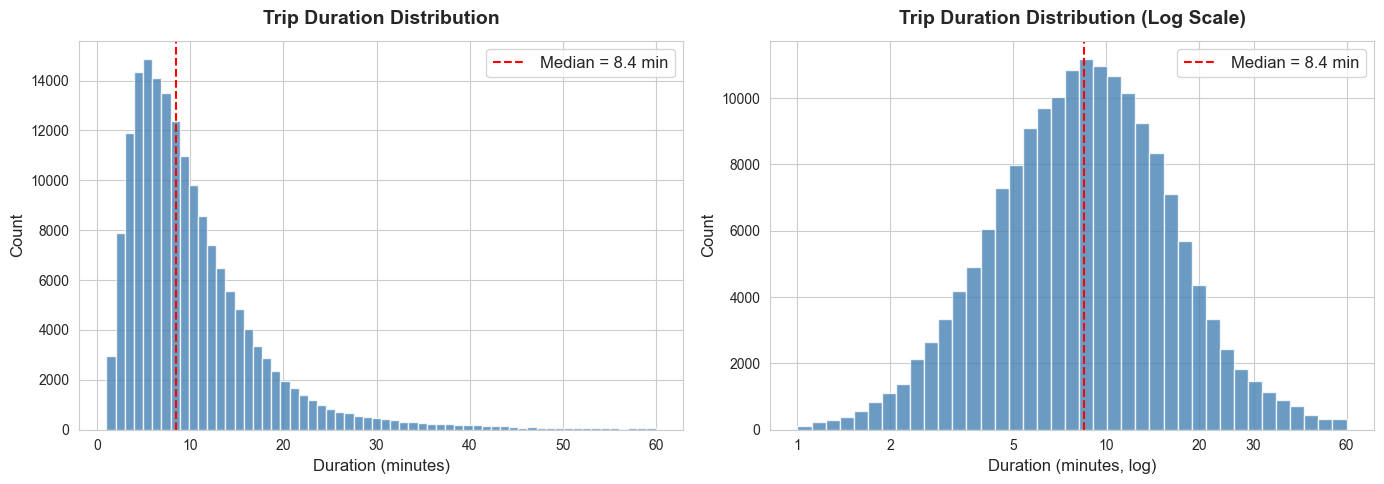

In [6]:
# Plot 1: Histogram of trip duration (log scale)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: raw scale
axes[0].hist(df['duration_min'], bins=60, edgecolor='white', color='steelblue', alpha=0.8)
format_plot(axes[0], 'Trip Duration Distribution', 'Duration (minutes)', 'Count')

# Right: log scale on x-axis for better visibility
log_bins = np.logspace(np.log10(1), np.log10(60), 40)
axes[1].hist(df['duration_min'], bins=log_bins, edgecolor='white', color='steelblue', alpha=0.8)
axes[1].set_xscale('log')
axes[1].xaxis.set_major_formatter(ticker.ScalarFormatter())
axes[1].set_xticks([1, 2, 5, 10, 20, 30, 60])
format_plot(axes[1], 'Trip Duration Distribution (Log Scale)', 'Duration (minutes, log)', 'Count')

# Add median line
median_dur = df['duration_min'].median()
for ax in axes:
    ax.axvline(median_dur, color='red', linestyle='--', linewidth=1.5, label=f'Median = {median_dur:.1f} min')
    ax.legend()

plt.tight_layout()
plt.show()


**Observations:**
- The distribution is **right-skewed** (log-normal shape). Most trips last **5–15 minutes**.
- The **median trip duration** is around 8–10 minutes, consistent with short urban commutes.
- The log-scale view reveals the distribution more clearly, confirming the log-normal pattern.

### Question 2: What is the breakdown of Subscribers vs Customers?

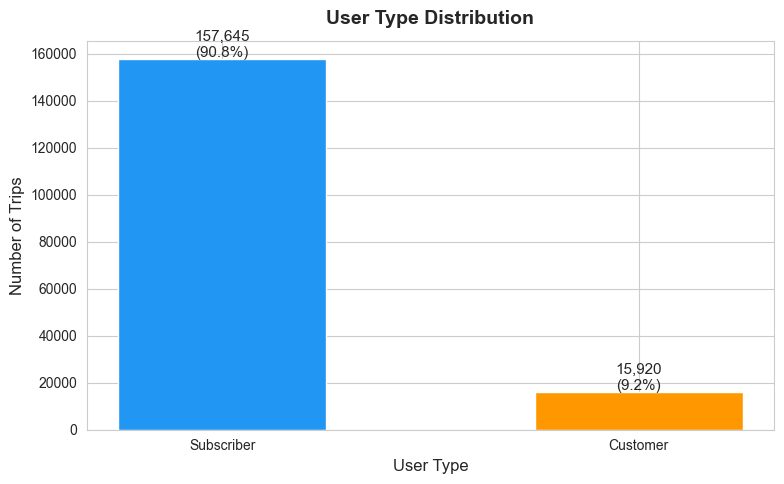

In [7]:
# Plot 2: Count plot of user_type
fig, ax = plt.subplots(figsize=(8, 5))
counts = df['user_type'].value_counts()
bars = ax.bar(counts.index, counts.values, color=['#2196F3', '#FF9800'], edgecolor='white', width=0.5)

# Add count labels on bars
for bar, count in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000,
            f'{count:,}\n({count/len(df)*100:.1f}%)', ha='center', fontsize=11)

format_plot(ax, 'User Type Distribution', 'User Type', 'Number of Trips')
plt.tight_layout()
plt.show()


**Observations:**
- **Subscribers** (annual members) vastly outnumber **Customers** (casual riders), making up ~90% of trips.
- This is typical for commuter-oriented bike-share systems.

### Question 3: What hours of the day are most popular for bike trips?

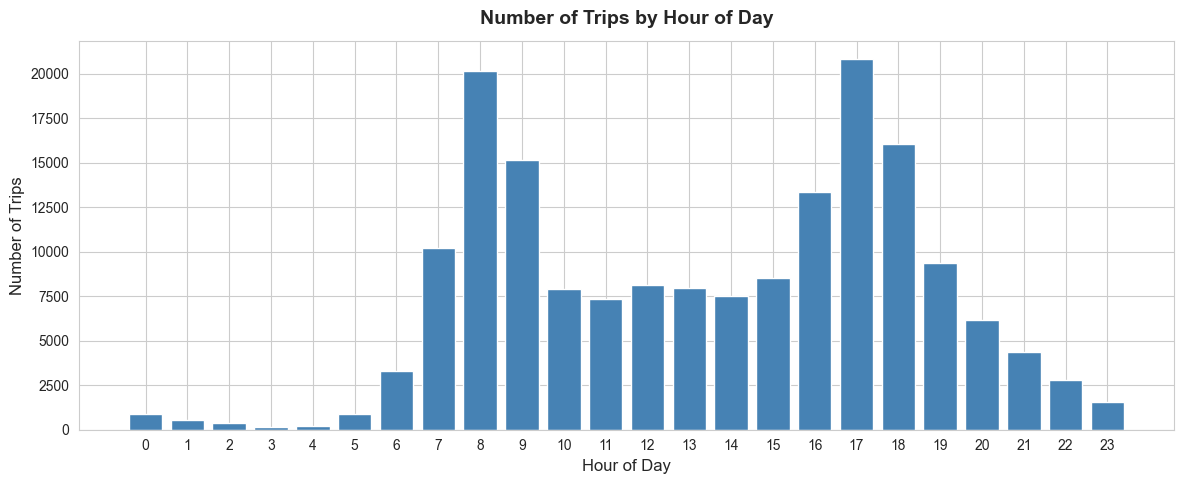

In [8]:
# Plot 3: Bar chart of trips by hour of day
fig, ax = plt.subplots(figsize=(12, 5))
hourly = df['hour'].value_counts().sort_index()
ax.bar(hourly.index, hourly.values, color='steelblue', edgecolor='white')
ax.set_xticks(range(0, 24))
format_plot(ax, 'Number of Trips by Hour of Day', 'Hour of Day', 'Number of Trips')
plt.tight_layout()
plt.show()


**Observations:**
- Clear **bimodal pattern** with peaks at **8–9 AM** and **5–6 PM** — classic commuter rush hours.
- Very few trips between midnight and 5 AM.
- This strongly suggests the system is heavily used for **work commutes**.

## Bivariate Exploration

### Question 4: Is there a relationship between the hour of day and trip duration?

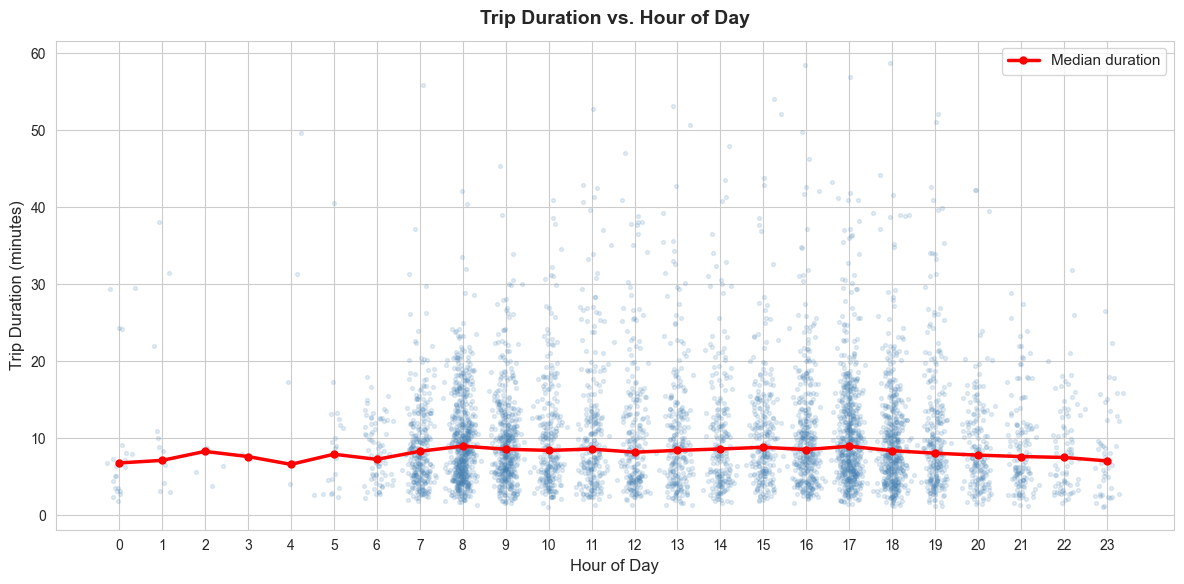

In [9]:
# Plot 4: Scatter plot of hour vs duration (sampled for readability)
fig, ax = plt.subplots(figsize=(12, 6))
sample = df.sample(n=5000, random_state=42)

ax.scatter(sample['hour'] + np.random.normal(0, 0.15, len(sample)),  # jitter
           sample['duration_min'],
           alpha=0.15, s=8, color='steelblue')

# Overlay median line per hour
hourly_med = df.groupby('hour')['duration_min'].median()
ax.plot(hourly_med.index, hourly_med.values, color='red', linewidth=2.5, marker='o',
        markersize=5, label='Median duration', zorder=5)

ax.set_xticks(range(0, 24))
format_plot(ax, 'Trip Duration vs. Hour of Day', 'Hour of Day', 'Trip Duration (minutes)')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


**Observations:**
- During **commute hours** (7–9 AM, 5–6 PM), trip durations are **tightly clustered** around the median — people ride efficiently.
- During **midday and weekends**, there's **more variance** — likely leisure riders taking longer trips.
- The median duration is relatively stable (8–12 min) across all hours.

### Question 5: Do Subscribers and Customers differ in trip duration?

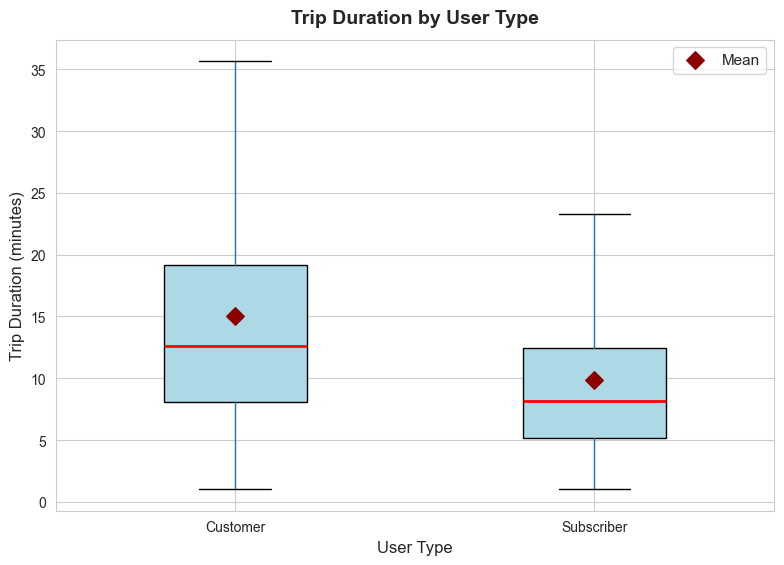

               count  mean  std  min  25%   50%   75%   max
user_type                                                  
Customer     15920.0  15.0  9.8  1.0  8.1  12.6  19.1  59.9
Subscriber  157645.0   9.8  6.9  1.0  5.2   8.2  12.4  59.9


In [10]:
# Plot 5: Box plot of duration by user_type
fig, ax = plt.subplots(figsize=(8, 6))
bp = df.boxplot(column='duration_min', by='user_type', ax=ax,
                patch_artist=True, widths=0.4,
                boxprops=dict(facecolor='lightblue'),
                medianprops=dict(color='red', linewidth=2),
                showfliers=False)  # hide outliers for clarity

# Add mean markers
means = df.groupby('user_type')['duration_min'].mean()
ax.scatter([1, 2], means.values, color='darkred', marker='D', s=80, zorder=5, label='Mean')

ax.set_title('')  # remove auto-title from boxplot
fig.suptitle('')
format_plot(ax, 'Trip Duration by User Type', 'User Type', 'Trip Duration (minutes)')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Print stats
print(df.groupby('user_type')['duration_min'].describe().round(1))


**Observations:**
- **Customers** have a **higher median and mean trip duration** than Subscribers.
- Subscribers take **shorter, more consistent** trips — reflecting routine commutes.
- Customers show **greater variability** — suggesting more exploratory or leisure riding.

### Question 6: How does trip volume vary across the week and throughout the day?

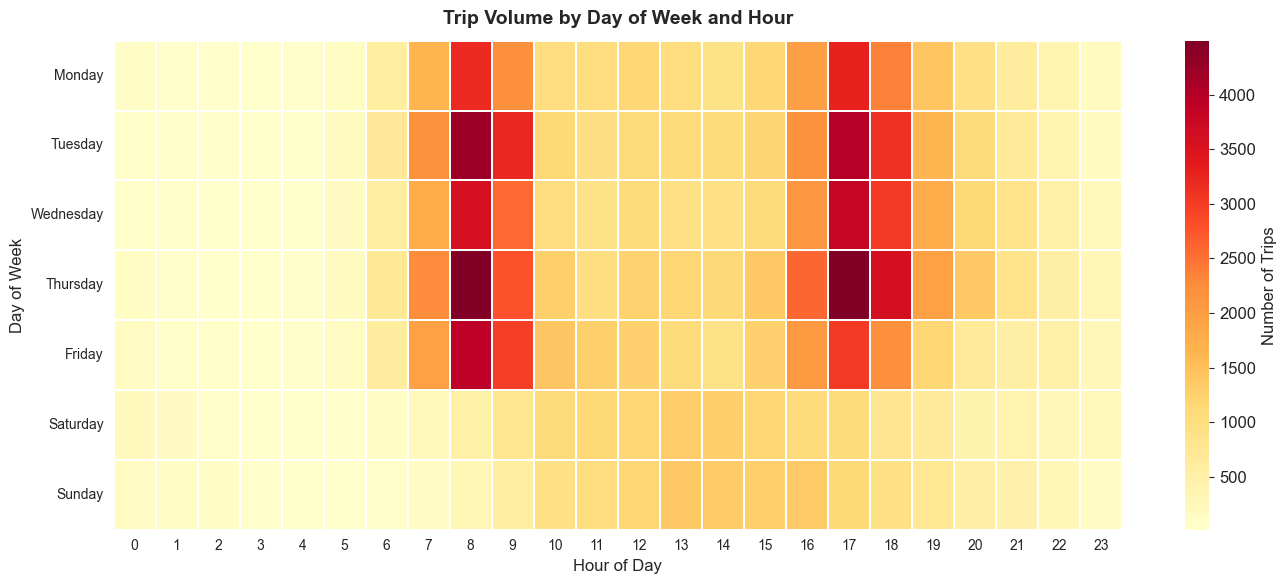

In [11]:
# Plot 6: Heatmap of trips by day_of_week × hour
fig, ax = plt.subplots(figsize=(14, 6))
pivot = df.groupby(['day_of_week', 'hour']).size().unstack(fill_value=0)

sns.heatmap(pivot, cmap='YlOrRd', annot=False, fmt='d', linewidths=0.3,
            cbar_kws={'label': 'Number of Trips'}, ax=ax)
format_plot(ax, 'Trip Volume by Day of Week and Hour', 'Hour of Day', 'Day of Week')
plt.tight_layout()
plt.show()


**Observations:**
- **Weekdays** show strong **commuter peaks** at 8 AM and 5 PM (two hot horizontal bands Mon–Fri).
- **Weekends** show a diffuse, spread-out pattern from late morning through evening — leisure usage.
- The contrast clearly separates **commuter** (weekday) from **recreational** (weekend) behavior.

## Multivariate Exploration

### Question 7: How does trip duration distribution differ across user types and days of the week?

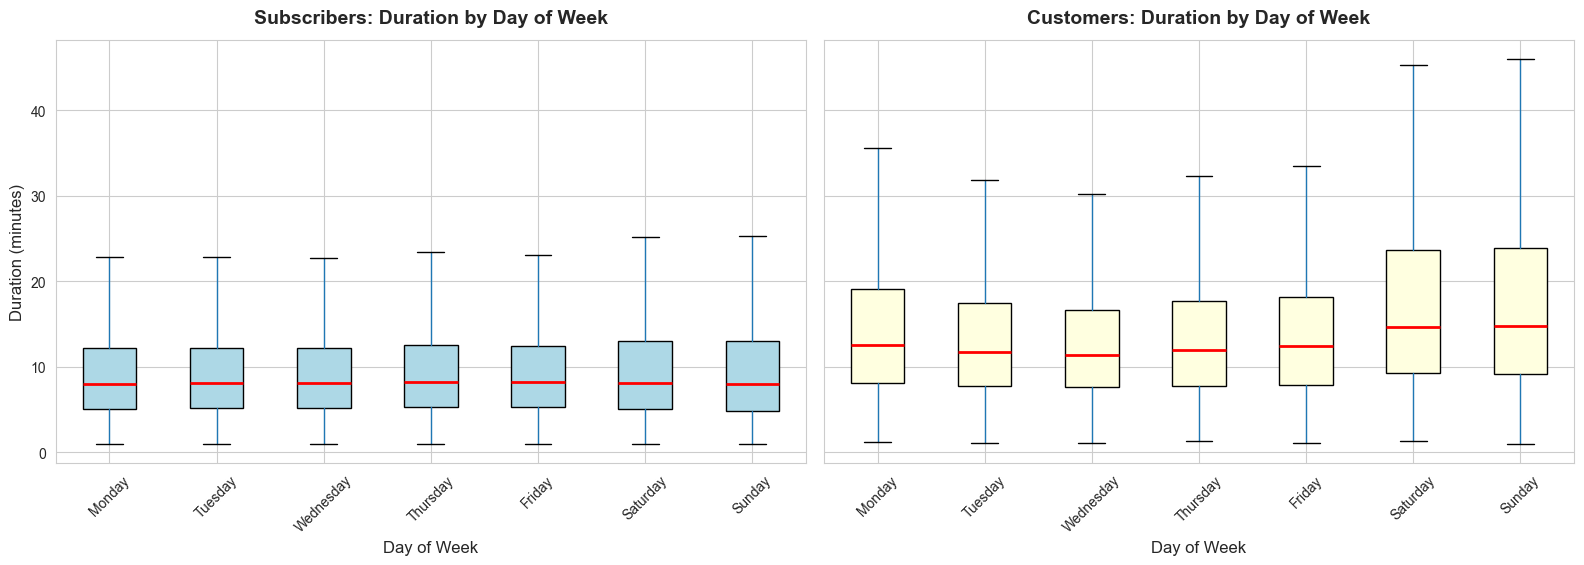

In [12]:
# Plot 7: Faceted violin/box plot — duration by user_type across days
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for i, utype in enumerate(['Subscriber', 'Customer']):
    subset = df[df['user_type'] == utype]
    subset.boxplot(column='duration_min', by='day_of_week', ax=axes[i],
                   patch_artist=True, showfliers=False, widths=0.5,
                   boxprops=dict(facecolor='lightblue' if utype == 'Subscriber' else 'lightyellow'),
                   medianprops=dict(color='red', linewidth=2))
    axes[i].set_title('')
    axes[i].get_figure().suptitle('')
    format_plot(axes[i], f'{utype}s: Duration by Day of Week',
                'Day of Week', 'Duration (minutes)' if i == 0 else '')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


**Observations:**
- **Subscribers** show remarkably **consistent duration** across all days — their median barely changes (~9–10 min).
- **Customers** ride **longer on weekends** (Saturday & Sunday), with higher medians and more spread.
- This confirms the two distinct personas: Subscribers = commuters (stable routine), Customers = leisure riders (weekend-heavy, longer trips).

### Question 8: How do hourly trip patterns differ between user types?

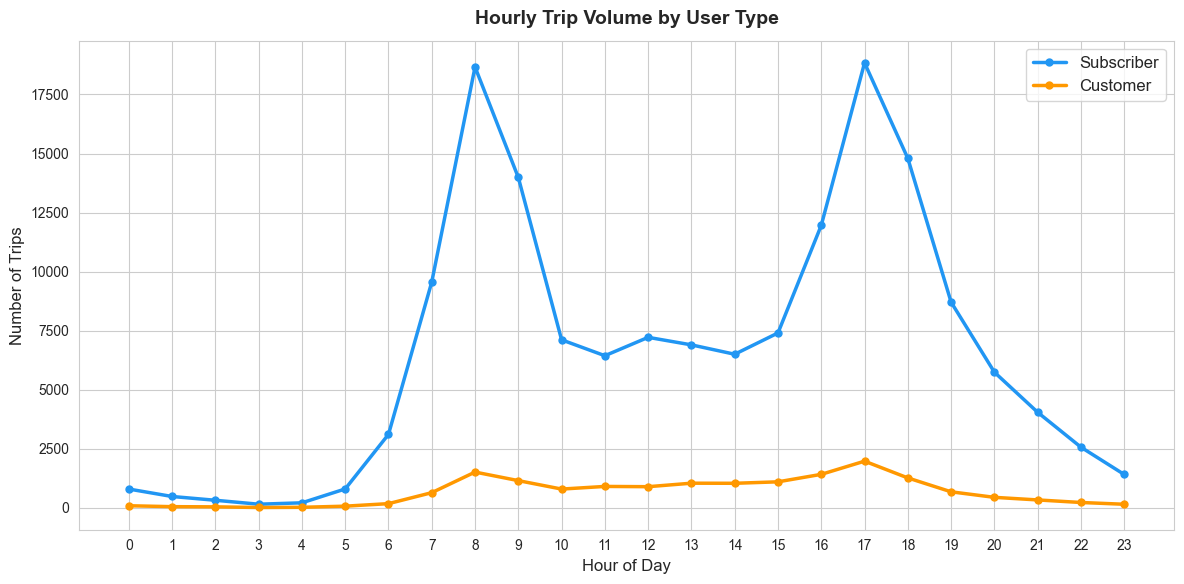

In [13]:
# Plot 8: Hourly trip counts by user_type (overlaid line chart)
fig, ax = plt.subplots(figsize=(12, 6))

for utype, color in [('Subscriber', '#2196F3'), ('Customer', '#FF9800')]:
    subset = df[df['user_type'] == utype]
    hourly = subset.groupby('hour').size()
    ax.plot(hourly.index, hourly.values, marker='o', linewidth=2.5,
            color=color, label=utype, markersize=5)

ax.set_xticks(range(0, 24))
format_plot(ax, 'Hourly Trip Volume by User Type', 'Hour of Day', 'Number of Trips')
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()


**Observations:**
- **Subscribers** drive the overall bimodal commute pattern (8–9 AM, 5–6 PM peaks).
- **Customers** show a **single broad peak** in the afternoon (12–5 PM) — leisure/tourist behavior.
- The subscriber curve dominates due to sheer volume, but the customer pattern is distinctly different in shape.

### Bonus: Pair plot of key numeric features by user type

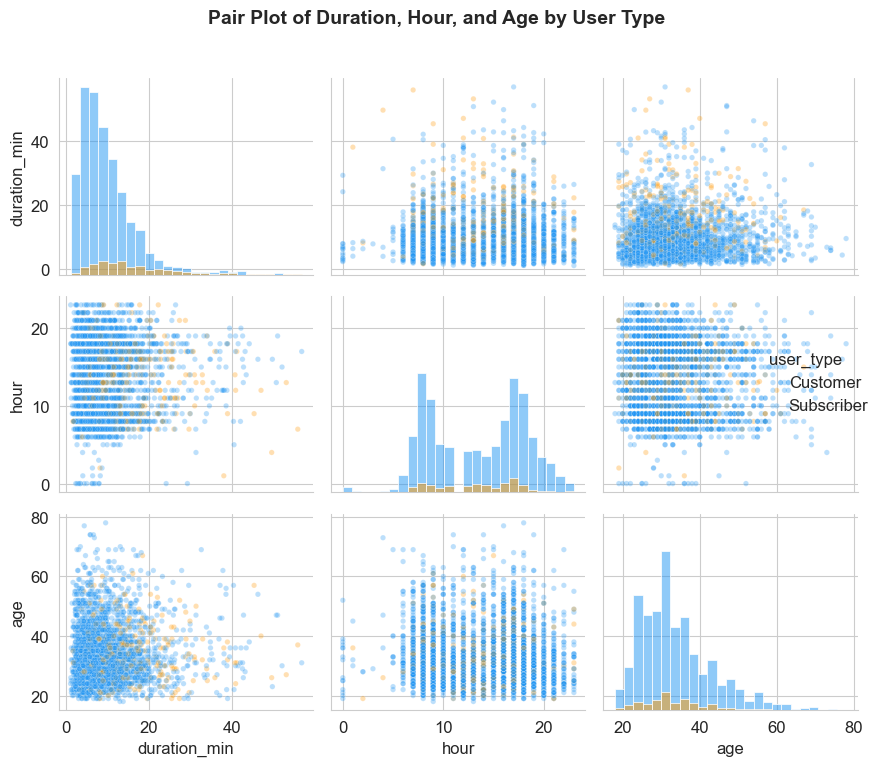

In [14]:
# Plot 9 (Bonus): Pair plot of numeric features colored by user_type
# Use a small sample to keep rendering fast
sample_pp = df[['duration_min', 'hour', 'age', 'user_type']].sample(n=3000, random_state=42)

g = sns.pairplot(sample_pp, hue='user_type', diag_kind='hist',
                 palette={'Subscriber': '#2196F3', 'Customer': '#FF9800'},
                 plot_kws={'alpha': 0.3, 's': 15},
                 diag_kws={'alpha': 0.5, 'bins': 25})
g.figure.suptitle('Pair Plot of Duration, Hour, and Age by User Type', y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Observations:**
- The pair plot confirms earlier findings: Customers skew toward longer durations and afternoon hours.
- Age distributions are similar between user types, peaking around 25–35.
- No strong linear correlations among the numeric variables, but the **user type separation** is visible in duration and hour dimensions.

## Conclusions

### Key Findings

1. **Trip duration is log-normally distributed**, with a median around 8–10 minutes. Most trips are short urban commutes.

2. **Subscribers dominate** the system (~90% of trips) and show clear **weekday commuter patterns** — bimodal peaks at 8 AM and 5 PM, consistent trip durations.

3. **Customers behave differently** — they ride **longer**, prefer **afternoons and weekends**, and show **more variability** in duration. This suggests leisure/tourist usage.

4. **The heatmap** powerfully reveals the weekday-vs-weekend contrast: sharp commute bands on weekdays, diffuse activity on weekends.

5. **Multivariate analysis** confirms that user type is the strongest differentiator in riding behavior, affecting both temporal patterns and trip duration.

### Reflection

The exploration followed a structured progression from univariate distributions to bivariate relationships to multivariate interactions. The most surprising finding was how cleanly the Subscriber/Customer distinction maps onto commuter/leisure patterns — it emerged consistently across every visualization. The log-scale histogram was essential for properly viewing the skewed duration distribution.
